# GruBI Programming exercise 3
Load the Hamming distances from the the `Hamming.tsv` file. Apply Jukes-Cantor correction and create a heatmap using matplotlib.

/var/folders/dk/gvz5_g4n70b13gg7xm1ng4wr0000gp/T/ipykernel_11938/552286430.py:45: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('viridis').copy()


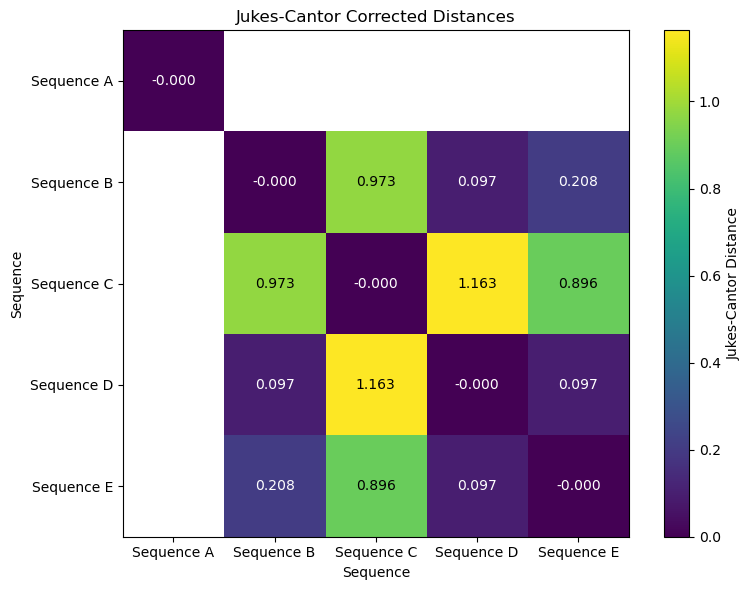

In [1]:
import math
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# Load distances from the provided file using standard library
sequences = []
distances = {}

# The provided TSV has no header and is formatted as "Seq1 \t Seq2 \t Distance"
with open('Hamming.tsv', 'r') as f:
    for line in f:
        parts = line.strip().split('\t')
        if len(parts) == 3:
            # Strip potential leading/trailing whitespaces
            seq1 = parts[0].strip()
            seq2 = parts[1].strip()
            dist = float(parts[2])
            
            # Maintain order of sequences
            if seq1 not in sequences:
                sequences.append(seq1)
            if seq2 not in sequences:
                sequences.append(seq2)
                
            distances[(seq1, seq2)] = dist

n = len(sequences)
jc_matrix = [[float('nan')] * n for _ in range(n)]

# Correct using Jukes-Cantor
# Formula: d = -3/4 * ln(1 - 4/3 * p)
for i, seq1 in enumerate(sequences):
    for j, seq2 in enumerate(sequences):
        dist = distances.get((seq1, seq2), -1.0)
        
        # A distance of -1 indicates different lengths (no Hamming distance).
        # Jukes-Cantor is mathematically undefined for p-distances >= 0.75.
        if dist != -1.0 and dist < 0.75:
            jc_matrix[i][j] = -0.75 * math.log(1 - (4.0/3.0) * dist)

# Create a heatmap using matplotlib
fig, ax = plt.subplots(figsize=(8, 6))

# Prepare a colormap that sets NaN values to appear as white/blank cells
cmap = cm.get_cmap('viridis').copy()
cmap.set_bad('white')

# Generate the heatmap using imshow
cax = ax.imshow(jc_matrix, cmap=cmap)

# Add colorbar
cbar = fig.colorbar(cax)
cbar.set_label('Jukes-Cantor Distance')

# Set ticks and labels
ax.set_xticks(range(n))
ax.set_yticks(range(n))
ax.set_xticklabels(sequences)
ax.set_yticklabels(sequences)

# Loop over data dimensions and create text annotations for the values
for i in range(n):
    for j in range(n):
        val = jc_matrix[i][j]
        if not math.isnan(val):
            # Choose text color based on background darkness for readability
            text_color = "w" if val < 0.5 else "k"
            ax.text(j, i, f"{val:.3f}", ha="center", va="center", color=text_color)

plt.title('Jukes-Cantor Corrected Distances')
plt.xlabel('Sequence')
plt.ylabel('Sequence')
plt.tight_layout()
plt.show()


### Analysis and Interpretation of Jukes-Cantor Distances

* **Unequal Sequence Lengths (Missing Values):** Sequence A has a raw distance of `-1` compared with all other sequences (B, C, D, E). This indicates that Sequence A has a different length compared to the rest, meaning no valid Hamming distance could be computed. In the heatmap, these comparisons are masked and appear as empty cells.
* **Effect of the Jukes-Cantor Correction:** The Jukes-Cantor model accounts for hidden multiple substitutions at the same nucleotide site over time. As raw Hamming distance (p-distance) increases, the Jukes-Cantor distance scales at a faster, non-linear rate. 
    * For closely related sequences (e.g., Sequence B and D with a raw distance of ~0.091), the corrected distance remains very similar (~0.097). 
    * However, for highly divergent sequences (e.g., Sequence C and D with a raw distance of ~0.591), the model heavily corrects the value, jumping significantly to a distance of ~1.163.
* **Clustering Observations:** Sequences B, D, and E are closely related to each other, evidenced by their short corrected distances (ranging between 0.097 and 0.203). Sequence C is highly divergent from B, D, and E, indicated by its much higher Jukes-Cantor distances (> 0.9) against all of them.
